# Part 3 — Customer Churn Prediction (ANN)
**ACS WIL Data Analytics | Predictive Analyst: Bao Ngoc Nguyen**  
**Dataset:** `Updated_Dataset_with_Clusters.csv` (received from the Data Engineer / Clustering Analyst)

## Business question
**Can we identify customers who are likely to leave the telecom company, so the business can prioritise retention activities?**

This notebook is designed to follow the style of Jyoti's Part 2: **objective → actions → evidence → plain-English interpretation → business value**. It builds and evaluates:

- **Benchmark:** Logistic Regression, a simple comparison model.
- **Model A:** ANN based on customer characteristics only.
- **Model B:** ANN with the same characteristics **plus four one-hot-encoded cluster labels**.

> **Important methodology note:** The `Cluster` column in the uploaded CSV was created using the entire dataset. It is useful for describing Jyoti's segmentation results, but we **do not directly use it in the main held-out ANN comparison**. Instead, K-Means is fitted using the *training data only* and is then used to label validation and test customers. This avoids using information from held-out customer profiles when creating the predictive feature.

> **Software:** Keras 3 runs with TensorFlow when available, or with a PyTorch backend otherwise. Both backends train a real feed-forward Artificial Neural Network. The code reports which backend is used.

### Roadmap
3.1 Load data and tools · 3.2 Data quality · 3.3 Encode inputs · 3.4 Understand churn · 3.5 Leakage-safe split · 3.6 Train-only scaling · 3.7 Simple benchmark · 3.8 ANN A · 3.9 ANN A evaluation · 3.10 K-Means feature · 3.11 ANN B · 3.12 Compare models · 3.13 Explain predictors · 3.14 Business implications · 3.15 Save outputs.

## 3.1 — Import tools and load the dataset
**Objective:** Read the same processed data produced in Parts 1 and 2.

**Plain English:** We start from the dataset already used for customer segmentation. This lets our prediction work build on the previous team's deliverables.

In [1]:
import os, importlib.util, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)
from sklearn.utils.class_weight import compute_class_weight

# Use TensorFlow if available; otherwise use the installed PyTorch backend for Keras 3.
os.environ['KERAS_BACKEND'] = 'tensorflow' if importlib.util.find_spec('tensorflow') else 'torch'
import keras
keras.utils.set_random_seed(42)
np.random.seed(42)
random.seed(42)
print('Keras version:', keras.__version__, '| Backend:', keras.backend.backend())

DATA_PATH = Path('Updated_Dataset_with_Clusters.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('/mnt/data/Updated_Dataset_with_Clusters.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Place Updated_Dataset_with_Clusters.csv next to this notebook.')

OUT_DIR = Path('ANN_outputs')
OUT_DIR.mkdir(exist_ok=True)
original = pd.read_csv(DATA_PATH)
print('Data shape:', original.shape)
display(original.head())

Keras version: 3.13.2 | Backend: torch
Data shape: (7043, 12)


,gender,SeniorCitizen,Dependents,tenure,MonthlyCharges,Churn,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,Contract_One year,Contract_Two year,Cluster
0,Female,-0.439916,No,-1.277445,-1.321350,Yes,False,False,False,False,False,0
1,Male,-0.439916,No,0.351370,-1.321350,No,True,False,False,True,False,2
2,Female,-0.439916,Yes,0.799294,-1.520755,No,True,False,False,False,False,2
3,Female,-0.439916,No,-1.277445,0.373593,Yes,True,False,False,True,False,1
4,Male,-0.439916,No,1.410099,-0.457261,No,True,False,True,False,False,2


## 3.2 — Data quality and readiness
**Objective:** Identify what the incoming dataset contains and what still requires attention.

**What we know:** 7,043 customer records; 12 columns including `Churn` and `Cluster`; zero missing values; 302 exact duplicate rows.

**Why it matters:** We do **not** delete 302 rows automatically. Without a genuine customer identifier, identical characteristics could belong to different customers. Instead, we protect evaluation by separating identical **input profiles** between training, validation and test sets.

In [2]:
print('Number of rows:', len(original))
print('Number of columns:', len(original.columns))
print('Missing values:', int(original.isna().sum().sum()))
print('Exact duplicate rows:', int(original.duplicated().sum()))
print('\nColumn types:\n', original.dtypes.to_string())
print('\nExisting cluster membership:\n', original['Cluster'].value_counts().sort_index().to_string())

Number of rows: 7043
Number of columns: 12
Missing values: 0
Exact duplicate rows: 302

Column types:
 gender                          object
SeniorCitizen                  float64
Dependents                      object
tenure                         float64
MonthlyCharges                 float64
Churn                           object
PhoneService_Yes                  bool
MultipleLines_Yes                 bool
InternetService_Fiber optic       bool
Contract_One year                 bool
Contract_Two year                 bool
Cluster                          int64

Existing cluster membership:
 Cluster
0    1721
1    2223
2    1176
3    1923


## 3.3 — Prepare the target and customer features
**Objective:** Convert fields into a format an ANN can understand.

**Specific issue in this file:** `gender` and `Dependents` are still text. `SeniorCitizen` was previously standardised (its two numeric values are approximately −0.440 and +2.273); it is **not** an unscaled 0/1 flag.

We convert:
- Male → 1, Female → 0
- Dependents Yes → 1, No → 0
- SeniorCitizen higher of its two observed values → 1; lower value → 0
- Other True/False features → 1/0
- Churn Yes → 1 (left), No → 0 (stayed)

**Important:** No `raw` dataframe was uploaded. We reconstruct the binary senior-citizen flag from the *two observed values in this file* rather than calling `raw['SeniorCitizen']`. The `Cluster` column is **not** treated as a target.

In [3]:
df = original.copy()
assert set(df['gender'].unique()) == {'Male', 'Female'}, 'Unexpected gender values; inspect manually.'
assert set(df['Dependents'].unique()) == {'Yes', 'No'}, 'Unexpected Dependents values.'
assert set(df['Churn'].unique()) == {'Yes', 'No'}, 'Unexpected Churn values.'

senior_values = sorted(df['SeniorCitizen'].unique())
assert len(senior_values) == 2, 'Expected two distinct values for SeniorCitizen.'
df['gender'] = (df['gender'] == 'Male').astype(int)
df['Dependents'] = (df['Dependents'] == 'Yes').astype(int)
df['SeniorCitizen'] = df['SeniorCitizen'].map({senior_values[0]: 0, senior_values[1]: 1}).astype(int)
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

feature_cols = ['gender', 'SeniorCitizen', 'Dependents', 'tenure', 'MonthlyCharges',
                'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic',
                'Contract_One year', 'Contract_Two year']
for col in feature_cols:
    df[col] = pd.to_numeric(df[col]).astype('float32')

X = df[feature_cols].copy()
y = df['Churn'].to_numpy(dtype='int32')
print('ANN input columns:', feature_cols)
print('Input feature count:', len(feature_cols))
print('SeniorCitizen counts after recovery:\n', df['SeniorCitizen'].value_counts().sort_index())
print('Churn class counts (0 = stayed, 1 = left):\n', df['Churn'].value_counts().sort_index())

ANN input columns: ['gender', 'SeniorCitizen', 'Dependents', 'tenure', 'MonthlyCharges', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'Contract_One year', 'Contract_Two year']
Input feature count: 10
SeniorCitizen counts after recovery:
 SeniorCitizen
0.0    5901
1.0    1142
Name: count, dtype: int64
Churn class counts (0 = stayed, 1 = left):
 Churn
0    5174
1    1869
Name: count, dtype: int64


## 3.4 — Understand class imbalance
**Objective:** Understand how often churn happens before evaluating predictions.

**Plain English:** About 26.5% of customers left, while 73.5% stayed. A model that predicts **everyone stays** would appear 73.5% accurate but fail to identify any customers who actually leave.

**Decision:** Evaluate more than accuracy, particularly **recall** (how many actual churners are detected) as well as **precision** (how many alerts are valid), F1 and ROC-AUC.

          Customers  Percent
Churn                       
No churn       5174    73.46
Churn          1869    26.54


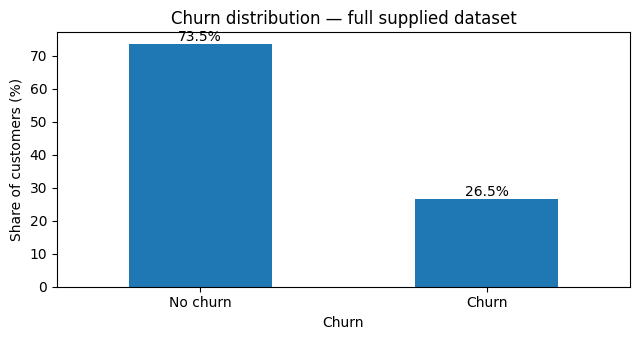

In [4]:
churn_counts = df['Churn'].map({0:'No churn',1:'Churn'}).value_counts().reindex(['No churn','Churn'])
churn_pct = churn_counts / len(df) * 100
print(pd.DataFrame({'Customers': churn_counts, 'Percent': churn_pct.round(2)}))
fig, ax = plt.subplots(figsize=(6.5,3.5))
churn_pct.plot(kind='bar', ax=ax)
ax.set_title('Churn distribution — full supplied dataset')
ax.set_ylabel('Share of customers (%)')
ax.tick_params(axis='x', rotation=0)
for p in ax.patches: ax.annotate(f'{p.get_height():.1f}%', (p.get_x()+p.get_width()/2,p.get_height()), ha='center', va='bottom')
plt.tight_layout()
plt.savefig(OUT_DIR/'01_churn_distribution.png', dpi=160)
plt.show()

## 3.5 — Split into training, validation and test sets (without duplicate-profile overlap)
**Objective:** Make the evaluation as fair as possible.

**Plan:** Approximately 64% training, 16% validation and 20% testing, preserving churn proportions as much as possible.

**Why group-aware splitting?** The 302 duplicate *rows* are retained, but identical customer input profiles are kept within only one split. This avoids training on a profile identical to one in the test set, which could make evaluation overly optimistic.

**Training:** teaches the ANN. **Validation:** selects settings/stops training. **Test:** provides an independent final check.

> We cannot guarantee that two different profiles represent two different people because CustomerID is missing. This limitation should be disclosed in the final report.

In [5]:
# Group by ALL predictive attributes, excluding Churn and Cluster.
# Exact same input profile will not appear across train/validation/test.
groups = pd.util.hash_pandas_object(X, index=False).to_numpy()
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
dev_idx, test_idx = next(outer_cv.split(X, y, groups=groups))

inner_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=43)
train_rel, val_rel = next(inner_cv.split(X.iloc[dev_idx], y[dev_idx], groups=groups[dev_idx]))
train_idx, val_idx = dev_idx[train_rel], dev_idx[val_rel]

X_train_raw = X.iloc[train_idx].copy()
X_val_raw = X.iloc[val_idx].copy()
X_test_raw = X.iloc[test_idx].copy()
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]

assert set(groups[train_idx]).isdisjoint(groups[val_idx])
assert set(groups[train_idx]).isdisjoint(groups[test_idx])
assert set(groups[val_idx]).isdisjoint(groups[test_idx])

split_info = pd.DataFrame({'Rows':[len(train_idx),len(val_idx),len(test_idx)],
                          'Churn rate':[y_train.mean(),y_val.mean(),y_test.mean()]},
                         index=['Train','Validation','Test'])
print('Protected against identical input profiles across splits: YES')
display(split_info.style.format({'Churn rate':'{:.2%}'}))

Protected against identical input profiles across splits: YES


,Rows,Churn rate
Train,4508,26.55%
Validation,1127,26.53%
Test,1408,26.49%


## 3.6 — Scale numerical features using training data only
**Objective:** Put the continuous features on a common scale without giving the training process information from the test set.

The Data Engineer had already standardised `tenure` and `MonthlyCharges` using the full dataset. We **re-standardise them using a scaler fitted only to our training split**. Since the earlier transformation is linear, this effectively re-centres both variables relative to the training data.

The other input columns are binary 0/1. We do not scale them for the ANN.

In [6]:
numeric_cols = ['tenure','MonthlyCharges']
ann_scaler = StandardScaler().fit(X_train_raw[numeric_cols])

def prepare_ann_X(frame):
    output = frame.copy()
    output.loc[:, numeric_cols] = ann_scaler.transform(frame[numeric_cols])
    return output.to_numpy(dtype='float32')

X_train_A = prepare_ann_X(X_train_raw)
X_val_A = prepare_ann_X(X_val_raw)
X_test_A = prepare_ann_X(X_test_raw)
print('Model A matrix shapes:', X_train_A.shape, X_val_A.shape, X_test_A.shape)
print('First processed training row:', np.round(X_train_A[0], 3))

Model A matrix shapes: (4508, 10) (1127, 10) (1408, 10)
First processed training row: [ 1.     0.     0.     0.354 -1.321  1.     0.     0.     1.     0.   ]


## 3.7 — Simple benchmark: Logistic Regression
**Objective:** Check whether the ANN is more useful than a simpler supervised-learning model.

**Plain English:** Choosing an ANN does not mean it will always be better. A simple benchmark provides a meaningful reference for performance. Class weights are used because churn is less common than non-churn.

In [7]:
baseline = LogisticRegression(max_iter=1500, class_weight='balanced', random_state=42)
baseline.fit(X_train_A, y_train)
base_probs = baseline.predict_proba(X_test_A)[:,1]

def metrics_at_half(name, y_true, probs):
    pred = (np.asarray(probs) >= 0.5).astype('int32')
    return {'Model':name, 'Accuracy':accuracy_score(y_true,pred),
            'Precision':precision_score(y_true,pred,zero_division=0),
            'Recall':recall_score(y_true,pred,zero_division=0),
            'F1':f1_score(y_true,pred,zero_division=0),
            'ROC-AUC':roc_auc_score(y_true,probs)}

benchmark_result = metrics_at_half('Logistic Regression',y_test,base_probs)
print(pd.DataFrame([benchmark_result]).round(3).to_string(index=False))

              Model  Accuracy  Precision  Recall    F1  ROC-AUC
Logistic Regression     0.751      0.521   0.777 0.624    0.838


## 3.8 — Build and train ANN Model A (without clusters)
**Objective:** Predict churn from the ten customer attributes alone.

**Architecture (starting point):** Input → Dense(32, ReLU) → Dropout(20%) → Dense(16, ReLU) → Output(1, Sigmoid). The sigmoid output is a churn probability between 0 and 1.

**Why these choices?** Two small hidden layers allow flexible relationships while limiting model complexity on a modest dataset. Dropout, modest regularisation and early stopping are intended to reduce overfitting. Class weights make mistakes on the minority churn class more costly during training.

**Important:** This is a **candidate architecture**, not proof it is optimal.

In [8]:
class_labels = np.array([0,1])
class_weight_values = compute_class_weight('balanced', classes=class_labels, y=y_train)
class_weights = {int(k):float(v) for k,v in zip(class_labels,class_weight_values)}
print('Training class weights:', class_weights)

def build_ann(input_dim, seed=42):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.layers.Input(shape=(input_dim,)),
        keras.layers.Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l2(0.0001)),
        keras.layers.Dropout(0.20),
        keras.layers.Dense(16, activation='relu'),
        keras.layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy', keras.metrics.AUC(name='auc')])
    return model

def fit_ann(train_x, val_x, seed):
    model = build_ann(train_x.shape[1], seed=seed)
    stopper = keras.callbacks.EarlyStopping(monitor='val_loss', patience=9,
                                            restore_best_weights=True)
    history = model.fit(train_x, y_train,
                        validation_data=(val_x,y_val),
                        batch_size=128, epochs=75,
                        callbacks=[stopper], class_weight=class_weights, verbose=0)
    print('Epochs completed:', len(history.history['loss']),
          '| Final training loss:',round(history.history['loss'][-1],4),
          '| Best validation loss:',round(min(history.history['val_loss']),4))
    return model, history

model_A, history_A = fit_ann(X_train_A, X_val_A, seed=42)
model_A.summary()

Training class weights: {0: 0.6807610993657506, 1: 1.8830409356725146}


Epochs completed: 27 | Final training loss: 0.527 | Best validation loss: 0.5321


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,693 (10.52 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,796 (7.02 KB)

## 3.9 — Inspect ANN A's learning curve and test predictions
**Objective:** Show evidence that the model has learned and check its ability to generalise.

**How to read the learning curve:** Training loss describes how well the model fits the training data; validation loss describes performance on unseen validation data. If training loss continues improving but validation loss worsens, the model may be overfitting. Early stopping helps limit this.

**How to read test metrics:** Recall reveals missed churners; precision reveals unnecessary retention alerts. Neither metric alone tells the full story.

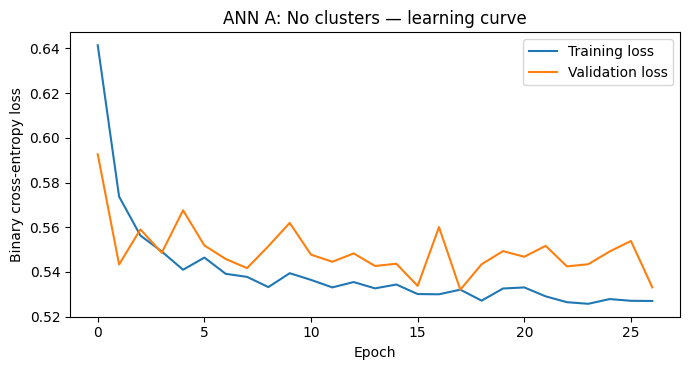

                   Model  Accuracy  Precision  Recall    F1  ROC-AUC
ANN A: Customer features      0.75      0.519   0.751 0.614    0.838

Confusion matrix (rows = actual; columns = predicted):
 [[776 259]
 [ 93 280]]


In [9]:
def draw_history(hist, name, filename):
    fig, ax = plt.subplots(figsize=(7,3.8))
    ax.plot(hist.history['loss'], label='Training loss')
    ax.plot(hist.history['val_loss'], label='Validation loss')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Binary cross-entropy loss')
    ax.set_title(name + ' — learning curve')
    ax.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR/filename,dpi=160)
    plt.show()

draw_history(history_A,'ANN A: No clusters','02_ann_a_learning.png')
probs_A = model_A.predict(X_test_A, verbose=0).ravel()
result_A = metrics_at_half('ANN A: Customer features', y_test, probs_A)
print(pd.DataFrame([result_A]).round(3).to_string(index=False))
print('\nConfusion matrix (rows = actual; columns = predicted):\n',confusion_matrix(y_test, probs_A>=0.5))

## 3.10 — Add cluster membership safely for ANN Model B
**Objective:** Test whether segmentation adds useful predictive information.

**Jyoti's result:** The uploaded `Cluster` column identifies four groups with different churn patterns. Those descriptive results are valuable and are **not changed** in our report.

**Fair ANN experiment:** However, the existing cluster labels were calculated on the full dataset. For Model B, we independently fit K-Means with K=4 on **training customers only**, using the same nine types of clustering inputs as Part 2 (all prepared customer features except gender and Churn). Then we predict clusters for validation and test customers. We one-hot encode these four cluster categories before adding them to ANN inputs.

**Important:** Refitted K-Means labels may use different cluster numbers than Jyoti's original C0–C3; cluster numbers are arbitrary. We compare **model quality**, not numeric cluster-name identity.

In [10]:
cluster_feature_cols = [c for c in feature_cols if c != 'gender']
# Reproduce the basic feature strategy of Jyoti's clustering: scale numeric measurements
# (and the 0/1 senior-citizen feature, as previously standardised); leave other flags 0/1.
cluster_scale_cols = ['tenure','MonthlyCharges','SeniorCitizen']
cluster_scaler = StandardScaler().fit(X_train_raw[cluster_scale_cols])

def prepare_cluster_X(frame):
    values = frame[cluster_feature_cols].copy()
    values.loc[:,cluster_scale_cols] = cluster_scaler.transform(frame[cluster_scale_cols])
    return values.to_numpy(dtype='float32')

cluster_train_X = prepare_cluster_X(X_train_raw)
cluster_val_X = prepare_cluster_X(X_val_raw)
cluster_test_X = prepare_cluster_X(X_test_raw)
train_only_kmeans = KMeans(n_clusters=4, n_init=20, random_state=42)
cluster_train = train_only_kmeans.fit_predict(cluster_train_X)
cluster_val = train_only_kmeans.predict(cluster_val_X)
cluster_test = train_only_kmeans.predict(cluster_test_X)

cluster_encoder = OneHotEncoder(categories=[list(range(4))], sparse_output=False,
                                handle_unknown='ignore')
cluster_encoder.fit(cluster_train.reshape(-1,1))
cluster_train_hot = cluster_encoder.transform(cluster_train.reshape(-1,1)).astype('float32')
cluster_val_hot = cluster_encoder.transform(cluster_val.reshape(-1,1)).astype('float32')
cluster_test_hot = cluster_encoder.transform(cluster_test.reshape(-1,1)).astype('float32')

X_train_B = np.hstack([X_train_A,cluster_train_hot])
X_val_B = np.hstack([X_val_A,cluster_val_hot])
X_test_B = np.hstack([X_test_A,cluster_test_hot])
print('Model A inputs:',X_train_A.shape[1], '| Model B inputs:',X_train_B.shape[1])
print('Model B includes 4 new one-hot cluster columns.')
print('Train-only K-Means cluster counts:\n',pd.Series(cluster_train).value_counts().sort_index())

Model A inputs: 10 | Model B inputs: 14
Model B includes 4 new one-hot cluster columns.
Train-only K-Means cluster counts:
 0    1253
1    1158
2     744
3    1353
Name: count, dtype: int64


## 3.11 — Build and train ANN Model B (with cluster labels)
**Objective:** Assess whether clustering improves an otherwise identical ANN.

**Fair comparison:** We use the **same ANN architecture**, same train/validation/test customer splits, same class-weight strategy, and same evaluation threshold (0.5). The only intended change is the four new cluster indicators.

Epochs completed: 27 | Final training loss: 0.5259 | Best validation loss: 0.5292


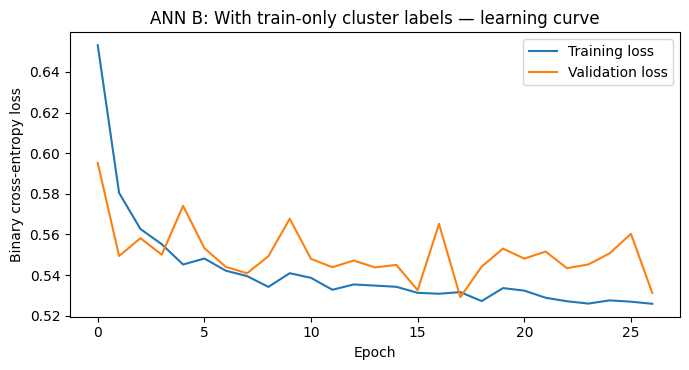

                     Model  Accuracy  Precision  Recall    F1  ROC-AUC
ANN B: Features + clusters     0.759      0.532   0.748 0.622    0.839


In [11]:
model_B, history_B = fit_ann(X_train_B, X_val_B, seed=42)
draw_history(history_B,'ANN B: With train-only cluster labels','03_ann_b_learning.png')
probs_B = model_B.predict(X_test_B, verbose=0).ravel()
result_B = metrics_at_half('ANN B: Features + clusters',y_test,probs_B)
print(pd.DataFrame([result_B]).round(3).to_string(index=False))

## 3.12 — Model comparison and error analysis
**Objective:** Determine which model delivers stronger generalisation and explain the trade-offs.

**Metrics:**
- **Accuracy:** proportion of all customers correctly classified.
- **Precision:** among predicted churners, the proportion who actually churned.
- **Recall:** among actual churners, the proportion the model found.
- **F1:** balance between precision and recall.
- **ROC-AUC:** how well the model ranks churners above non-churners across thresholds.

**Business relevance:** False negatives are customers who leave but are not flagged for retention. False positives are customers flagged as at risk who would have stayed. The business needs to decide which error is more costly.

**Interpretation rule:** Only claim that clusters help if Model B performs better on meaningful metrics. Do not assume ANN B is better merely because it has more inputs.

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.751,0.521,0.777,0.624,0.838
ANN A: Customer features,0.750,0.519,0.751,0.614,0.838
ANN B: Features + clusters,0.759,0.532,0.748,0.622,0.839


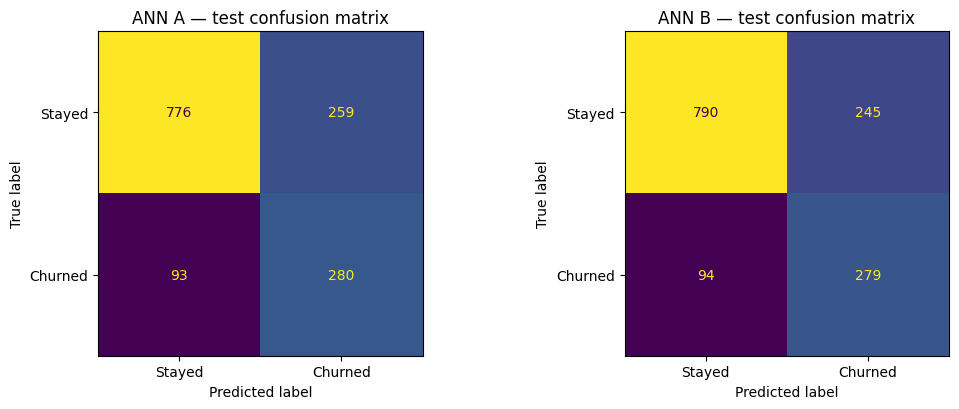

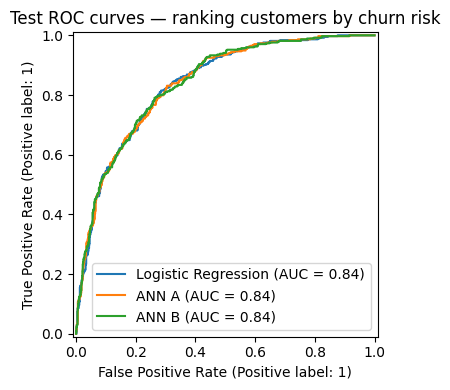

ANN A: Found 280 of 373 churners (recall 75.1%); missed 93 churners; flagged 259 customers who stayed.
ANN B: Found 279 of 373 churners (recall 74.8%); missed 94 churners; flagged 245 customers who stayed.
ROC-AUC difference (ANN B - ANN A): +0.001
ROC-AUC is very similar; extra cluster features provide little clear benefit here.


In [12]:
comparison = pd.DataFrame([benchmark_result,result_A,result_B]).set_index('Model')
display(comparison.style.format('{:.3f}'))
comparison.to_csv(OUT_DIR/'ANN_Model_Comparison.csv')

fig,axs=plt.subplots(1,2,figsize=(11,4.2))
for ax,name,probs in zip(axs,['ANN A','ANN B'],[probs_A,probs_B]):
    ConfusionMatrixDisplay.from_predictions(y_test,probs>=0.5, ax=ax, colorbar=False,
                                           display_labels=['Stayed','Churned'])
    ax.set_title(name+' — test confusion matrix')
plt.tight_layout()
plt.savefig(OUT_DIR/'04_confusion_matrices.png',dpi=160)
plt.show()

fig,ax=plt.subplots(figsize=(6.5,4))
RocCurveDisplay.from_predictions(y_test,base_probs,ax=ax,name='Logistic Regression')
RocCurveDisplay.from_predictions(y_test,probs_A,ax=ax,name='ANN A')
RocCurveDisplay.from_predictions(y_test,probs_B,ax=ax,name='ANN B')
ax.set_title('Test ROC curves — ranking customers by churn risk')
plt.tight_layout()
plt.savefig(OUT_DIR/'05_roc_curves.png',dpi=160)
plt.show()

for name,probs in [('ANN A',probs_A),('ANN B',probs_B)]:
    tn,fp,fn,tp=confusion_matrix(y_test,probs>=0.5).ravel()
    print(f'{name}: Found {tp} of {tp+fn} churners (recall {tp/(tp+fn):.1%}); '
          f'missed {fn} churners; flagged {fp} customers who stayed.')

auc_difference = result_B['ROC-AUC']-result_A['ROC-AUC']
print(f'ROC-AUC difference (ANN B - ANN A): {auc_difference:+.3f}')
if auc_difference > .01:
    print('ANN B has higher test ROC-AUC; check the other metrics before preferring it.')
elif auc_difference < -.01:
    print('ANN B has lower test ROC-AUC; cluster indicators do not improve ranking here.')
else:
    print('ROC-AUC is very similar; extra cluster features provide little clear benefit here.')

## 3.13 — What inputs are associated with ANN predictions?
**Objective:** Give stakeholders some explanation beyond a performance score.

We use **permutation importance** on the **ANN A test inputs**: shuffle one feature at a time and measure the drop in ROC-AUC. A large drop suggests the model relies more heavily on that feature for its predictions.

**Caution:** This is an approximate measure of *predictive reliance*, **not evidence of causation**. Correlated features can share importance, and a small importance value does not prove a feature has no business significance.

,Feature,Mean ROC-AUC decrease
3,tenure,0.241
4,MonthlyCharges,0.116
5,PhoneService_Yes,0.009
1,SeniorCitizen,0.008
2,Dependents,0.003
7,InternetService_Fiber optic,0.001
0,gender,0.001
8,Contract_One year,0.001
9,Contract_Two year,-0.000
6,MultipleLines_Yes,-0.001


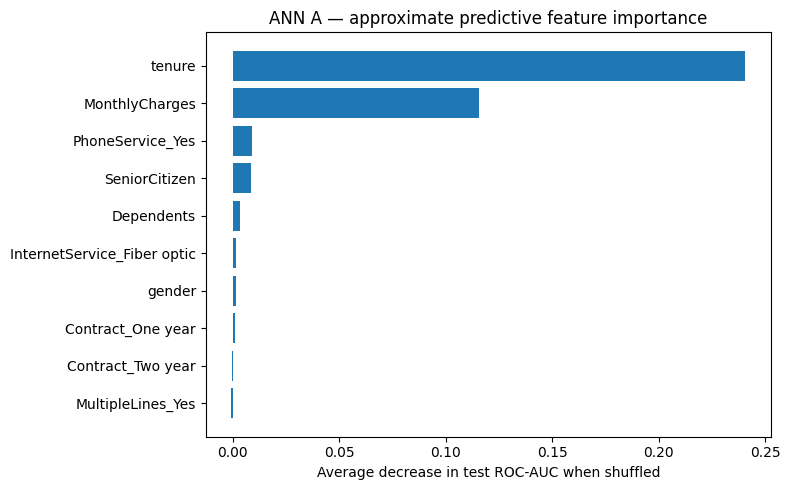

In [ ]:
rng = np.random.default_rng(42)
base_auc_A = roc_auc_score(y_test,probs_A)
importances=[]
for j, name in enumerate(feature_cols):
    drops=[]
    for repeat in range(3):
        perm = X_test_A.copy()
        perm[:,j] = rng.permutation(perm[:,j])
        perm_probs = model_A.predict(perm,verbose=0).ravel()
        drops.append(base_auc_A - roc_auc_score(y_test,perm_probs))
    importances.append((name, float(np.mean(drops))))
importance_df = pd.DataFrame(importances,columns=['Feature','Mean ROC-AUC decrease']).sort_values('Mean ROC-AUC decrease',ascending=False)
display(importance_df.round(3))
importance_df.to_csv(OUT_DIR/'ANN_Feature_Importance.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
ax.barh(importance_df['Feature'][::-1], importance_df['Mean ROC-AUC decrease'][::-1])
ax.set_xlabel('Average decrease in test ROC-AUC when shuffled')
ax.set_title('ANN A — approximate predictive feature importance')
plt.tight_layout()
plt.savefig(OUT_DIR/'06_feature_importance.png',dpi=160)
plt.show()
print('Most influential feature in this analysis:',importance_df.iloc[0]['Feature'])

## 3.14 — Turn predictions into business insights
**Objective:** Connect ANN results to customer retention decisions.

**Plain English:** An ANN returns a **risk score**, not a confirmed prediction about someone's future. The Business Analyst could use high-risk scores to suggest who should receive further attention, but the company should evaluate costs, fairness and business constraints before launching any campaign.

**Connections to Jyoti's findings:** Her four segments show different observed churn rates. ANN can add an *individual* estimate inside each segment. We report test-set prediction performance honestly and avoid suggesting this historical snapshot establishes why anyone churned.

**Limitations:** No unique CustomerID; 302 duplicate rows retained; only one snapshot; no detailed payment history or service quality data; a moderate dataset size; and possible changes in customer behaviour over time.

> **Suggested next experiment:** Tune the decision threshold on validation data using a defined business target (e.g. achieve high recall while keeping the volume of false alerts manageable). Avoid choosing a threshold based on the test set.

In [ ]:
# Analysis-only table: original Jyoti labels and descriptive churn rates.
# These original full-data cluster labels are NOT used in ANN training/test preparation.
cluster_descriptive = original.assign(ChurnFlag=(original['Churn']=='Yes').astype(int)).groupby('Cluster').agg(
    Customers=('ChurnFlag','size'), Churn_rate=('ChurnFlag','mean')).reset_index()
cluster_descriptive['Churn_rate'] = (cluster_descriptive['Churn_rate']*100).round(1)
print('Original Part 2 segmentation — descriptive results:')
display(cluster_descriptive)

# Held-out ANN predictions. RowNumber is a DATASET ROW INDEX, NOT a CustomerID.
# Choose the ANN candidate using VALIDATION ROC-AUC rather than test ROC-AUC.
val_probs_A = model_A.predict(X_val_A, verbose=0).ravel()
val_probs_B = model_B.predict(X_val_B, verbose=0).ravel()
val_auc_A = roc_auc_score(y_val, val_probs_A)
val_auc_B = roc_auc_score(y_val, val_probs_B)
best_ann_name = 'ANN B' if val_auc_B > val_auc_A else 'ANN A'
print('Validation ROC-AUC — ANN A:', round(val_auc_A,3), '| ANN B:',round(val_auc_B,3))
chosen_probs = probs_B if best_ann_name=='ANN B' else probs_A
predictions = pd.DataFrame({
    'DatasetRowNumber':test_idx,
    'ActualChurn':y_test,
    'ChurnProbability_ANN_A':probs_A,
    'ChurnProbability_ANN_B':probs_B,
    'PredictedChurn_ChosenModel':(chosen_probs>=0.5).astype(int),
    'JyotiOriginalCluster_DescriptiveOnly':original.iloc[test_idx]['Cluster'].to_numpy()
}).sort_values('DatasetRowNumber')
predictions.to_csv(OUT_DIR/'ANN_Test_Predictions.csv',index=False)
print('Example held-out test predictions (numbers identify rows, not people):')
display(predictions.head(8))
print('Preferred ANN from VALIDATION ROC-AUC:',best_ann_name)
print('Test predictions are reported only for independent evaluation.')

## 3.15 — Save outputs for the project team
**Deliverables:**
- `ANN_Model_Comparison.csv` — results against the same held-out customers.
- `ANN_Test_Predictions.csv` — illustrative row-level test predictions (dataset row number is **not** CustomerID).
- `ANN_Feature_Importance.csv` — model reliance, not causal findings.
- PNG charts — class balance, training curves, confusion matrices, ROC curves, feature importance.

**Meeting-ready explanation (plain English):**

> I used the processed dataset from the Data Engineer and the segmentation findings from Jyoti. First, I encoded the remaining categorical fields and prepared leakage-aware training, validation and test sets. I trained a simple benchmark and two ANN models: one without cluster labels and another with clustering information generated from training data only. I evaluated the models using accuracy, precision, recall, F1 and ROC-AUC, and interpreted their errors in terms of missed churners and unnecessary retention alerts. The final outputs can support the Business Analyst in prioritising customer retention, but the findings are predictive associations rather than proven causes.

**Important reproducibility note:** This code uses the available Keras backend and random seeds. Results may vary slightly by computer, operating system, and installed versions. Please report the actual values displayed after running the notebook on your system.

In [ ]:
print('Files saved under',OUT_DIR.resolve())
for file in sorted(OUT_DIR.iterdir()):
    print(' -',file.name)